# QuantumXCT — ovarian cancer co/mono (object-oriented version)

OO reproduction of `qxct_pred_sc_cocultured_monocultured.py` using `QuantumXct` + `RunConfig`. The original script is left untouched.

**Convention:** mono-culture (Mo) = basal/initial, co-culture (Co) = target. Cancer cells = cell 1 (`gl_ct1`, q0..q3), fibroblasts = cell 2 (`gl_ct2`, q4..q6). Run from the `python/` folder so `dataset_co_mo2.h5ad` resolves.

In [1]:
import numpy as np
import pandas as pd
import scanpy as sc

from qxct import (
    QuantumXct, RunConfig,
    EncodingConfig, BackendConfig, SearchConfig, OptimizerConfig, MitigationConfig,
    build_optimized_circuit, plot_measurement_histograms,
    analyze_and_summarize_network, plot_quantum_relay_network, save_results,
)
from qxct.encoding import create_joint_histogram, plot_joint_histogram

np.random.seed(42)

C:\Users\selim\miniconda3\envs\qiskit-env\Lib\site-packages\scanpy\_utils\__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
C:\Users\selim\miniconda3\envs\qiskit-env\Lib\site-packages\scanpy\__init__.py:36: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
C:\Users\selim\miniconda3\envs\qiskit-env\Lib\site-packages\scanpy\readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


## 1. Load & preprocess

In [2]:
adata = sc.read_h5ad("dataset_co_mo2.h5ad")
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 7890 × 13125
    obs: 'CellID', 'BatchID', 'ClusterID', 'CellType', 'CellCycle'
    uns: 'log1p'

## 2. Gene lists

In [3]:
gl_ct1 = ['PDGFB', 'STAT3', 'HES4', 'TGFB1']   # cancer cells  -> q0..q3
gl_ct2 = ['PDGFRB', 'TGFBR1', 'TGFBR2']         # fibroblasts   -> q4..q6
gl_all = gl_ct1 + gl_ct2
gl_all

['PDGFB', 'STAT3', 'HES4', 'TGFB1', 'PDGFRB', 'TGFBR1', 'TGFBR2']

## 3. Subset by BatchID and binarize (> 0)

In [4]:
from scipy.sparse import issparse

def _mat(a):
    return a.X.toarray() if issparse(a.X) else a.X

# Co-culture -> target
Xct1_co = _mat(adata[adata.obs["BatchID"] == "Cancer Cells (Co)", gl_ct1])
Xct2_co = _mat(adata[adata.obs["BatchID"] == "Fibroblasts (Co)",  gl_ct2])
# Mono-culture -> basal
Xct1_mo = _mat(adata[adata.obs["BatchID"] == "Cancer Cells (Mo)", gl_ct1])
Xct2_mo = _mat(adata[adata.obs["BatchID"] == "Fibroblasts (Mo)",  gl_ct2])

Xct1_binary_co = (Xct1_co > np.mean(Xct1_co, axis=0) * 0).astype(int)
Xct2_binary_co = (Xct2_co > np.mean(Xct2_co, axis=0) * 0).astype(int)
Xct1_binary_mo = (Xct1_mo > np.mean(Xct1_mo, axis=0) * 0).astype(int)
Xct2_binary_mo = (Xct2_mo > np.mean(Xct2_mo, axis=0) * 0).astype(int)

## 4. Joint histograms

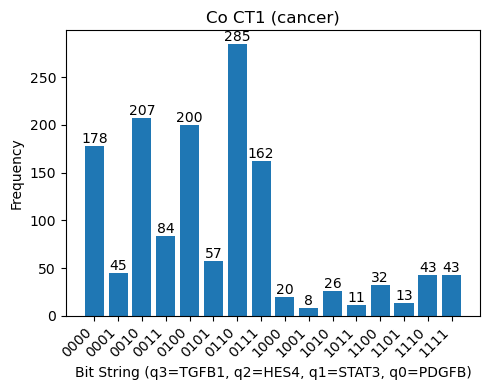

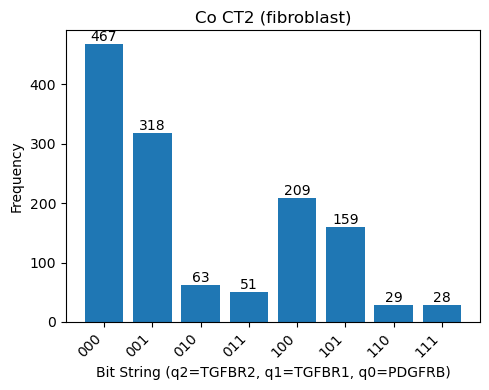

In [5]:
joint_counts_ct1_co, _ = create_joint_histogram(Xct1_binary_co)
joint_counts_ct2_co, _ = create_joint_histogram(Xct2_binary_co)
joint_counts_ct1_mo, _ = create_joint_histogram(Xct1_binary_mo)
joint_counts_ct2_mo, _ = create_joint_histogram(Xct2_binary_mo)

plot_joint_histogram(joint_counts_ct1_co, num_qubits=len(gl_ct1), features=gl_ct1, title='Co CT1 (cancer)')
plot_joint_histogram(joint_counts_ct2_co, num_qubits=len(gl_ct2), features=gl_ct2, title='Co CT2 (fibroblast)')

## 5. Configure the run

`threshold=0.01`, `search_mode="pos"`, `nshots=5000` — matching the original.

In [6]:
config = RunConfig(
    encoding=EncodingConfig(norm="l1"),
    backend=BackendConfig(shots=5000),
    search=SearchConfig(
        algorithm="multi_epoch",       # or 'iterative_n_wise' as in the original first block
        candidate_scope="all",
        threshold=0.01, search_mode="pos",
        n_epochs=None, kl_tol=0.05, max_greedy_depth=30,
    ),
    optimizer=OptimizerConfig(method="COBYLA", initial_angle=np.pi / 2),
    mitigation=MitigationConfig(dynamical_decoupling=True, twirling_gates=True,
                                twirling_measure=True, measurement_mitigation=True,
                                resilience_level=1, shots=5000),
)

## 6. Run the pipeline

In [7]:
qx = QuantumXct(config, gene_list=gl_all)
qx.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)

result = qx.run()
print("Best topology :", result.topology)
print("CRX angles    :", [round(a, 3) for a in result.angles])
print("Final KL sum  :", round(result.kl_sum, 4))
result.contribution_df


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 28 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 28
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/28 (Addition) with CNOT: (3, 4) (KL: 0.177607) ---
    --> Found a better KL on this path: 0.075955 at depth 2 with added CNOT (4, 0)
    --> Found a better KL on this path: 0.056274 at depth 3 with added CNOT (0, 4)
    --> Found a better KL on this path: 0.045773 at depth 4 with added CNOT (6, 1)
  KL Sum (0.045773) below tolerance. Early stopping this epoch.
  Epoch 1 best KL Sum: 0.045773
  --> Epoch 1 found a new overall best KL Sum: 0.045773

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.045773)
  No CNOT removal improved the score. Stopping removal search.

--- Starting Epoch 2/28 (Addition) with CN

,Step,Interaction,CRX Angle (rad),KL Divergence,KL Change,Cumulative KL Reduction,Isolated KL,Isolated Reduction,% Contribution,% Isolated Contribution,CRX Angle (deg)
0,0,Baseline (0 gates),NaN,0.189151,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,NaN
1,1,TGFB1 -> PDGFRB,2.622392,0.169941,-0.019210,-0.019210,0.169941,0.019210,10.155935,10.155935,150.251985
2,2,PDGFRB -> PDGFB,1.937327,0.057435,-0.112505,-0.131715,0.079639,0.109512,59.479165,57.896680,111.000635


## 7. Optimized-circuit histograms


--- Running circuit for: CRX-Optimized (OO) ---
Counts for c_measure1: {'0101': 228, '0110': 1395, '0010': 862, '0000': 488, '0011': 295, '0111': 530, '1110': 105, '0100': 623, '1000': 17, '1010': 65, '1101': 34, '1111': 108, '0001': 121, '1011': 63, '1100': 45, '1001': 21}
Counts for c_measure2: {'001': 997, '000': 2273, '100': 750, '010': 297, '101': 374, '011': 147, '110': 121, '111': 41}


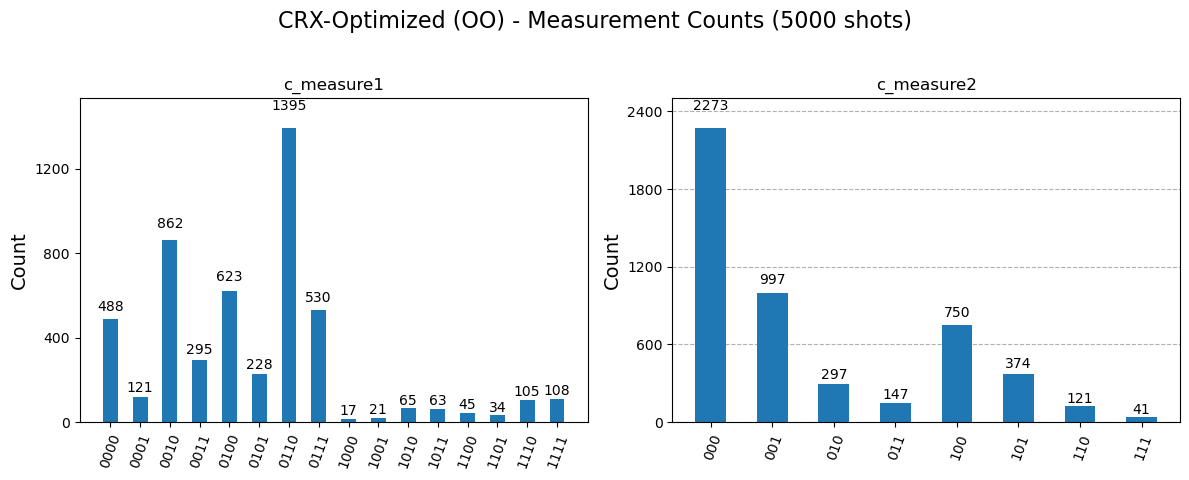

({'0101': 228,
  '0110': 1395,
  '0010': 862,
  '0000': 488,
  '0011': 295,
  '0111': 530,
  '1110': 105,
  '0100': 623,
  '1000': 17,
  '1010': 65,
  '1101': 34,
  '1111': 108,
  '0001': 121,
  '1011': 63,
  '1100': 45,
  '1001': 21},
 {'001': 997,
  '000': 2273,
  '100': 750,
  '010': 297,
  '101': 374,
  '011': 147,
  '110': 121,
  '111': 41})

In [8]:
final_circ = build_optimized_circuit(qx.circ1, qx.circ2, result.topology, result.angles)
plot_measurement_histograms(final_circ, nshots=5000, title_prefix="CRX-Optimized (OO)")

## 8. Relay-network plot with ligand-receptor bridges

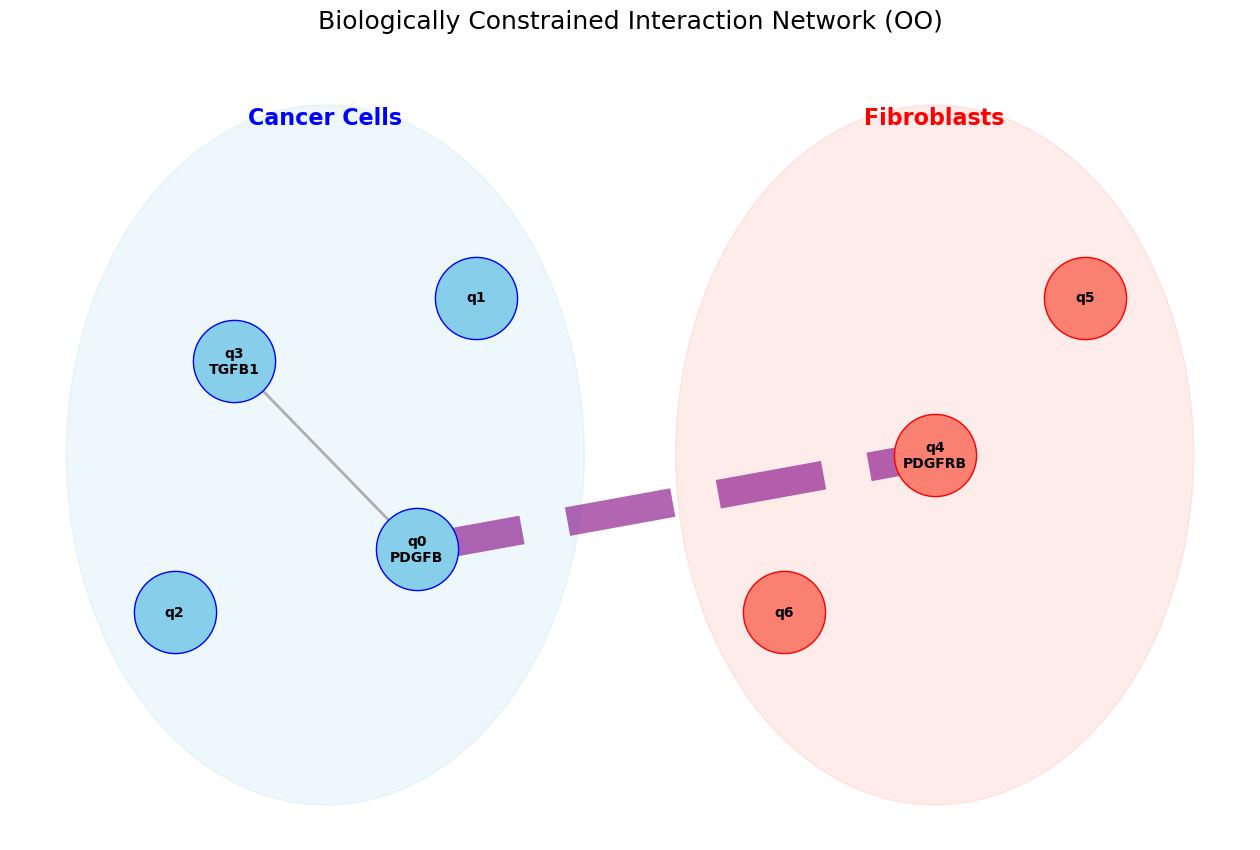

In [9]:
from qxct.resources import curate_lr_pairs
# LR pairs auto-curated from the Dimitrov/LIANA consensus DB, intersected with the
# genes in this test (replaces hand-curated pairs; plotting only).
valid_lr_pairs = curate_lr_pairs(gl_all, resource_csv="LR_databases/Human-merged-Jin-Dimitrov-LR-pairs.csv")
plot_quantum_relay_network(
    topology=result.topology,
    gene_list=gl_all,
    gl_ct1=gl_ct1, gl_ct2=gl_ct2,
    valid_lr_pairs=valid_lr_pairs,
    contribution_df=result.contribution_df,
    ct1_name="Cancer Cells", ct2_name="Fibroblasts",
    title="Biologically Constrained Interaction Network (OO)",
)

## 9. Save results

In [10]:
qx.save("results/ovarian_cancer_oo", metadata={"dataset": "dataset_co_mo2", "search_mode": "pos"})

Topology saved → results/ovarian_cancer_oo.json
Ablation results saved → results/ovarian_cancer_oo_ablation.csv


'results/ovarian_cancer_oo'

## Compare all search algorithms

Runs each `SearchConfig.algorithm` on the *same* data and tabulates gates / final KL / reduction, so you can compare **multi_epoch**, **iterative_n_wise** and **vqe_hybrid** side by side — the OO equivalent of the original script's separate search blocks.

`vqe_hybrid` builds an EfficientSU2 ansatz with one qubit per candidate CNOT, so it is the heaviest variant. Each run is kept in `algo_runs[...]` for further inspection (topology, angles, `assert_on_hardware`, `contribution_df`).


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 28 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 28
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/28 (Addition) with CNOT: (3, 4) (KL: 0.177607) ---
    --> Found a better KL on this path: 0.075955 at depth 2 with added CNOT (4, 0)
    --> Found a better KL on this path: 0.056274 at depth 3 with added CNOT (0, 4)
    --> Found a better KL on this path: 0.045773 at depth 4 with added CNOT (6, 1)
  KL Sum (0.045773) below tolerance. Early stopping this epoch.
  Epoch 1 best KL Sum: 0.045773
  --> Epoch 1 found a new overall best KL Sum: 0.045773

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.045773)
  No CNOT removal improved the score. Stopping removal search.

--- Starting Epoch 2/28 (Addition) with CN

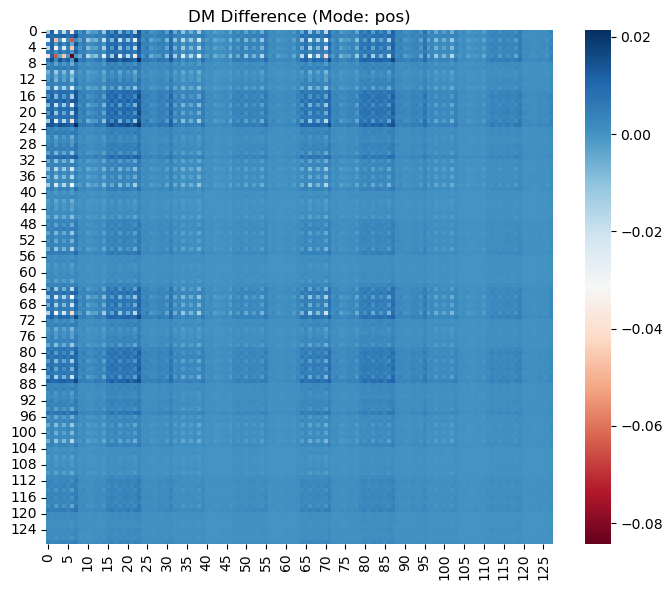


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 28 / 42
------------------------------

Number of initial CNOT candidates: 28
Initial KL-divergence: 0.189151

  - Starting Efficiency-Optimized Search -

--- Iteration 1 | Current KL: 0.189151 ---
   - Single Insertion Phase: Added (1, 0) at index 0. New KL: 0.128005
  [Phase 1] Added Single: (1, 0) | New KL: 0.128005
  [Phase 2] Added Pair: ((0, 1), (0, 4)) | New KL: 0.036384
  - Global Target KL met. Stopping.

--- Total Search Time: 192.37s ---

--- Pairwise Addition Result ---
Best sequence after addition: [(1, 0), (0, 1), (0, 4)]
KL sum after addition: 0.036384

Total search time: 192.97 seconds.

--- Starting CRX Angle Optimization (3 CRX gates) ---
Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 36   Least value of F = 0.021106077655209242   Constraint violation = 0.0
The corresponding X is:
[1.39443012 1.5499504  2.65364038]
The constraint value is:
[-1.394

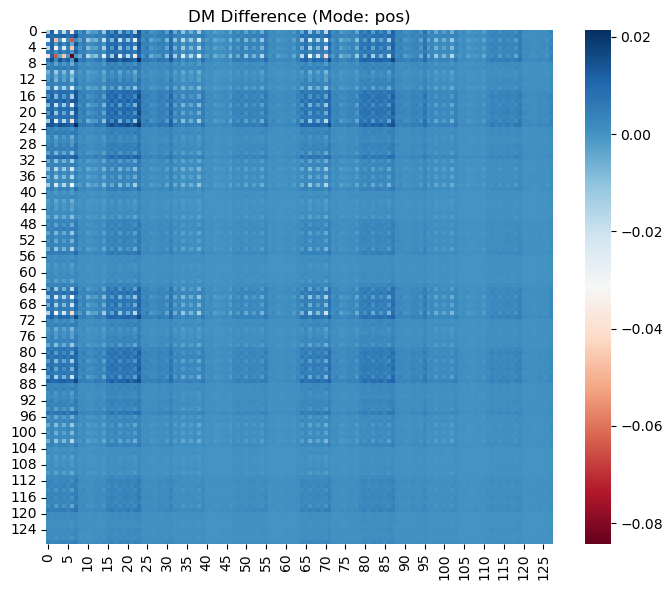


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 28 / 42
------------------------------

Initial KL Divergence (no CNOTs): 0.189151

--- Building KL Divergence Matrix (28x28) ---
Calculating KL for single CNOTs (diagonal elements)...
Calculating KL for CNOT pairs (off-diagonal elements)...
Total CNOT pairs tested: 756
--- KL Divergence Matrix Built ---
Starting optimization with method: COBYLA
Iteration 0: Current cost: -0.04169885797043212
Iteration 20: Current cost: -0.11269875909722317
Iteration 40: Current cost: -0.2949801171925509

Optimization Result:
 message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
 success: False
  status: 3
     fun: -0.324570932805551
       x: [ 1.954e+00  8.992e-01 ...  1.663e+00  1.663e+00]
    nfev: 200
   maxcv: 0.0

Final Energy: -0.324570932805551

Optimized Full Parameters:
  θ[0]: 1.9541567313862194
  θ[1]: 0.899234082981916
  θ[2]: 0.8254724692551907
  θ[3]: 1.1275784074026416
  θ[4]: 2.82

,algorithm,# gates,final KL,reduction,topology
0,multi_epoch,2,0.0574,0.1317,"[(3, 4), (4, 0)]"
1,iterative_n_wise,3,0.0211,0.1680,"[(1, 0), (0, 1), (0, 4)]"
2,vqe_hybrid,3,0.0381,0.1510,"[(0, 4), (6, 0), (2, 4)]"


In [11]:
import dataclasses
import pandas as pd
from qxct import baseline_kl

ALGORITHMS = ["multi_epoch", "iterative_n_wise", "vqe_hybrid"]
algo_runs, rows = {}, []
for algo in ALGORITHMS:
    s = dataclasses.replace(config.search, algorithm=algo)
    cfg_a = dataclasses.replace(config, search=s)
    qx_a = QuantumXct(cfg_a, gene_list=gl_all)
    qx_a.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)
    qx_a.screen_candidates()
    qx_a.search_topology()
    qx_a.optimize_angles()
    algo_runs[algo] = qx_a
    base = baseline_kl(qx_a.circ1, qx_a.circ2, qx_a.target1, qx_a.target2, cfg_a.backend.shots)
    rows.append({"algorithm": algo, "# gates": len(qx_a.result.topology),
                 "final KL": round(float(qx_a.result.kl_sum), 4),
                 "reduction": round(float(base - qx_a.result.kl_sum), 4),
                 "topology": qx_a.result.topology})

compare_df = pd.DataFrame(rows)
compare_df

### Scopes benchmark: LR / GRN / LR+GRN
Runs `compare_scopes` and defines `bench` used by the cells below.

In [12]:
# Scopes benchmark (LR / GRN / LR+GRN). This defines `bench`, which the next cell uses.
import os
from qxct.analysis import compare_scopes
OUT_DIR = "results/sc_cocultured"
os.makedirs(OUT_DIR, exist_ok=True)
bench = compare_scopes(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all,
)
bench["summary"].to_csv(os.path.join(OUT_DIR, "scope_summary.csv"), index=False)
bench["summary"]



--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 28 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 28
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/28 (Addition) with CNOT: (3, 4) (KL: 0.177607) ---
    --> Found a better KL on this path: 0.075955 at depth 2 with added CNOT (4, 0)
    --> Found a better KL on this path: 0.056274 at depth 3 with added CNOT (0, 4)
    --> Found a better KL on this path: 0.045773 at depth 4 with added CNOT (6, 1)
  KL Sum (0.045773) below tolerance. Early stopping this epoch.
  Epoch 1 best KL Sum: 0.045773
  --> Epoch 1 found a new overall best KL Sum: 0.045773

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.045773)
  No CNOT removal improved the score. Stopping removal search.

--- Starting Epoch 2/28 (Addition) with CN

,Scope,Baseline KL,Final KL,KL Reduction,% Reduction,# Gates
0,GRN + LR,0.189151,0.057435,0.131715,69.635100,2
1,GRN only (intra),0.189151,0.053799,0.135352,71.557858,2
2,LR only (inter),0.189151,0.075600,0.113550,60.031671,2


In [13]:
from qxct.analysis import plot_scope_report
gl_ct1_report, gl_ct2_report = gl_ct1, gl_ct2
from qxct.resources import curate_lr_pairs
# LR pairs auto-curated from the Dimitrov/LIANA consensus DB, intersected with the
# genes in this test (replaces hand-curated pairs; plotting only).
valid_lr_pairs = curate_lr_pairs(gl_all, resource_csv="LR_databases/Human-merged-Jin-Dimitrov-LR-pairs.csv")
ct1_name, ct2_name = 'Cancer Cells', 'Cancer Associated Fibroblasts'
# --- self-contained: (re)compute `bench` if it is not in the kernel, so this
# cell works on its own even after a kernel restart or out-of-order run ---
try:
    bench
except NameError:
    bench = compare_scopes(
        config,
        joint_counts_ct1_mo, joint_counts_ct2_mo,
        joint_counts_ct1_co, joint_counts_ct2_co,
        gene_list=gl_all,
    )

for scope, res in bench["detail"].items():
    tag = {"all": "GRN+LR", "intra": "GRN-only", "inter": "LR-only"}[scope]
    print("=" * 72)
    print(f"[{tag}]  {res['n_gates']} gates | baseline KL {res['baseline_kl']:.4f} "
          f"-> final KL {res['final_kl']:.4f}  (reduction {res['reduction']:.4f}, {res['pct_reduction']:.1f}%)")
    print("=" * 72)
    print("\nCumulative ablation reduction:")
    print(res["cumulative_ablation"].to_string(index=False))
    print("\nIsolated / leave-one-out gate contribution:")
    print(res["isolated_contribution"].to_string(index=False))
    res["cumulative_ablation"].to_csv(os.path.join(OUT_DIR, f"{scope}_cumulative_ablation.csv"), index=False)
    res["isolated_contribution"].to_csv(os.path.join(OUT_DIR, f"{scope}_isolated_contribution.csv"), index=False)
    # Full per-scope figure report: occupancy, optimized circuit,
    # measurement histograms, and interaction network by cell type.
    plot_scope_report(
        res, gl_ct1=gl_ct1_report, gl_ct2=gl_ct2_report,
        valid_lr_pairs=valid_lr_pairs, out_dir=OUT_DIR, scope=scope,
        ct1_name=ct1_name, ct2_name=ct2_name,
    )


[GRN+LR]  2 gates | baseline KL 0.1892 -> final KL 0.0574  (reduction 0.1317, 69.6%)

Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN       0.189151   0.000000                 0.000000       0.000000
    1    TGFB1 -> PDGFRB         2.622392       0.169941  -0.019210                 0.019210      10.155935
    2    PDGFRB -> PDGFB         1.937327       0.057435  -0.112505                 0.131715      69.635100

Isolated / leave-one-out gate contribution:
           Gate  CRX Angle (rad)  Isolated KL  Isolated Reduction  LOO KL (without gate)  Marginal Contribution  % Marginal of Baseline
PDGFRB -> PDGFB         1.937327     0.079639            0.109512               0.169941               0.112505               59.479165
TGFB1 -> PDGFRB         2.622392     0.169941            0.019210               0.079639               0.022203               11.73842

In [14]:
# Inspect any single scope further, e.g. the LR-only isolated contribution:
bench["detail"]["inter"]["isolated_contribution"]

,Gate,CRX Angle (rad),Isolated KL,Isolated Reduction,LOO KL (without gate),Marginal Contribution,% Marginal of Baseline
0,TGFBR2 -> PDGFB,1.641138,0.090735,0.098416,0.100758,0.025157,13.300046
1,TGFBR1 -> PDGFB,2.718077,0.100758,0.088393,0.090735,0.015134,8.001050
